# Banking Transaction Data Pipeline & Risk Analytics
## 01 - Exploratory Data Analysis (EDA)

This notebook explores the **raw synthetic banking transaction dataset** using
Python, Pandas, NumPy, Matplotlib and Seaborn.

Goals:
- Understand the shape and structure of the data
- Quantify data-quality problems (missing values, duplicates, invalid values)
- Explore univariate, bivariate and time-series patterns
- Explore customer-level and banking-specific patterns

Every chart below is created to answer a specific business question (stated
above the chart), not just for the sake of visualization.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

BASE_DIR = os.path.join(os.getcwd(), "..")
RAW_PATH = os.path.join(BASE_DIR, "data", "raw", "banking_transactions_raw.csv")
CHARTS_DIR = os.path.join(BASE_DIR, "outputs", "charts")
os.makedirs(CHARTS_DIR, exist_ok=True)

df = pd.read_csv(RAW_PATH)
df.shape

(55437, 25)

## A. Dataset Overview

In [2]:
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")
print(f"Memory usage: {df.memory_usage(deep=True).sum() / (1024**2):.2f} MB")
print(f"Unique customers: {df['customer_id'].nunique()}")
print(f"Unique accounts: {df['account_id'].nunique()}")
print(f"Unique branches: {df['branch'].nunique()}")
df.dtypes

Rows: 55437
Columns: 25
Memory usage: 61.75 MB
Unique customers: 4000
Unique accounts: 5176
Unique branches: 15


transaction_id                  object
customer_id                     object
account_id                      object
transaction_date                object
transaction_time                object
transaction_type                object
amount                         float64
balance_before                 float64
balance_after                  float64
account_type                    object
customer_age                   float64
customer_gender                 object
city                            object
state                           object
branch                          object
channel                         object
merchant_category               object
payment_method                  object
transaction_status              object
device_type                     object
is_international                 int64
country                         object
failed_attempts                  int64
previous_transaction_amount    float64
customer_risk_score            float64
dtype: object

In [3]:
df.head()

,transaction_id,customer_id,account_id,transaction_date,transaction_time,transaction_type,amount,balance_before,balance_after,account_type,...,channel,merchant_category,payment_method,transaction_status,device_type,is_international,country,failed_attempts,previous_transaction_amount,customer_risk_score
0,TXN00022591,CUST001632,ACC002123,2025-03-30,14:44:17,Debit,7292.79,26031.05,18738.26,Savings,...,Mobile Banking,Fuel,IMPS,Success,iOS,0,India,0,6563.51,2.3
1,TXN00030902,CUST002237,ACC002904,2025-03-16,06:59:41,Debit,373.53,91215.94,90842.41,Savings,...,POS,Travel,Credit Card,Success,POS Terminal,0,India,0,336.18,29.8
2,TXN00004033,CUST000298,ACC000386,2025-06-15,01:48:42,Debit,3332.45,500.00,0.00,Current,...,ATM,Grocery,Cash,Success,ATM Machine,0,India,0,1956.82,44.8
3,TXN00039482,CUST002863,ACC003706,2025-09-28,18:13:48,withdrawal,4443.07,61577.05,57133.98,Savings,...,Mobile Banking,Entertainment,NEFT,Success,Android,0,India,0,3972.13,44.3
4,TXN00021891,CUST001582,ACC002058,2025-12-08,14:30:24,debit,5787.39,37492.21,31704.82,Savings,...,POS,Utilities,Credit Card,Success,POS Terminal,0,India,0,1474.40,13.3


In [4]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
transaction_id,55437,54997,TXN00040477,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_id,55437,4000,CUST000940,37,NaN,NaN,NaN,NaN,NaN,NaN,NaN
account_id,55437,5176,ACC002111,26,NaN,NaN,NaN,NaN,NaN,NaN,NaN
transaction_date,55415,369,2025-02-26,190,NaN,NaN,NaN,NaN,NaN,NaN,NaN
transaction_time,55437,40836,07:55:43,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
transaction_type,55437,10,Debit,22656,NaN,NaN,NaN,NaN,NaN,NaN,NaN
amount,55437.0,NaN,NaN,NaN,5332.072898,6844.704734,-54368.03,1848.52,3396.73,6328.82,278097.41
balance_before,55437.0,NaN,NaN,NaN,51871.224367,36319.083667,500.0,22729.82,49625.06,76848.38,223906.79
balance_after,54884.0,NaN,NaN,NaN,49299.680992,36303.488541,-4315.15,19176.77,46416.2,74117.3175,291211.9
account_type,55437,2,Savings,41147,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## B. Data Quality Analysis

We quantify missing values, duplicates and invalid values in the **raw**
extract. These issues are fixed later in `python/data_cleaning.py`; here we
just measure them.

In [5]:
missing = df.isna().sum()
missing_pct = (missing / len(df) * 100).round(2)
pd.DataFrame({"missing_count": missing, "missing_pct": missing_pct}).query("missing_count > 0").sort_values("missing_count", ascending=False)

,missing_count,missing_pct
city,1107,2.00
merchant_category,830,1.50
customer_age,556,1.00
balance_after,553,1.00
payment_method,551,0.99
transaction_date,22,0.04


In [6]:
full_duplicates = df.duplicated().sum()
duplicate_txn_ids = df["transaction_id"].duplicated().sum()
print(f"Fully duplicated rows: {full_duplicates}")
print(f"Duplicate transaction_id values: {duplicate_txn_ids}")

Fully duplicated rows: 275
Duplicate transaction_id values: 440


In [7]:
invalid_amounts = (df["amount"] <= 0).sum()
print(f"Invalid (<=0) transaction amounts: {invalid_amounts}")

parsed_dates = pd.to_datetime(df["transaction_date"], errors="coerce", format="%Y-%m-%d")
print(f"Invalid transaction dates: {parsed_dates.isna().sum()}")

Invalid (<=0) transaction amounts: 275
Invalid transaction dates: 111


In [8]:
# Inconsistent capitalization example - payment_method
df["payment_method"].value_counts()

payment_method
Cash           11084
UPI             8593
NEFT            8586
IMPS            6471
Debit Card      6085
RTGS            4635
Credit Card     4615
cash            1063
CASH            1028
upi              487
Upi              456
DEBIT CARD       348
Debit card       336
debit card       335
credit card      283
Credit card      262
CREDIT CARD      219
Name: count, dtype: int64

In [9]:
# Outlier check on transaction amount using IQR
Q1, Q3 = df["amount"].quantile([0.25, 0.75])
IQR = Q3 - Q1
lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
outliers = df[(df["amount"] < lower) | (df["amount"] > upper)]
print(f"IQR bounds: [{lower:.2f}, {upper:.2f}]")
print(f"Number of amount outliers: {len(outliers)} ({len(outliers)/len(df)*100:.2f}% of data)")

IQR bounds: [-4871.93, 13049.27]
Number of amount outliers: 4335 (7.82% of data)


## C. Univariate Analysis

**Business question:** What does a typical transaction look like — in terms
of amount, customer age, type, payment method, channel, account type and
status?

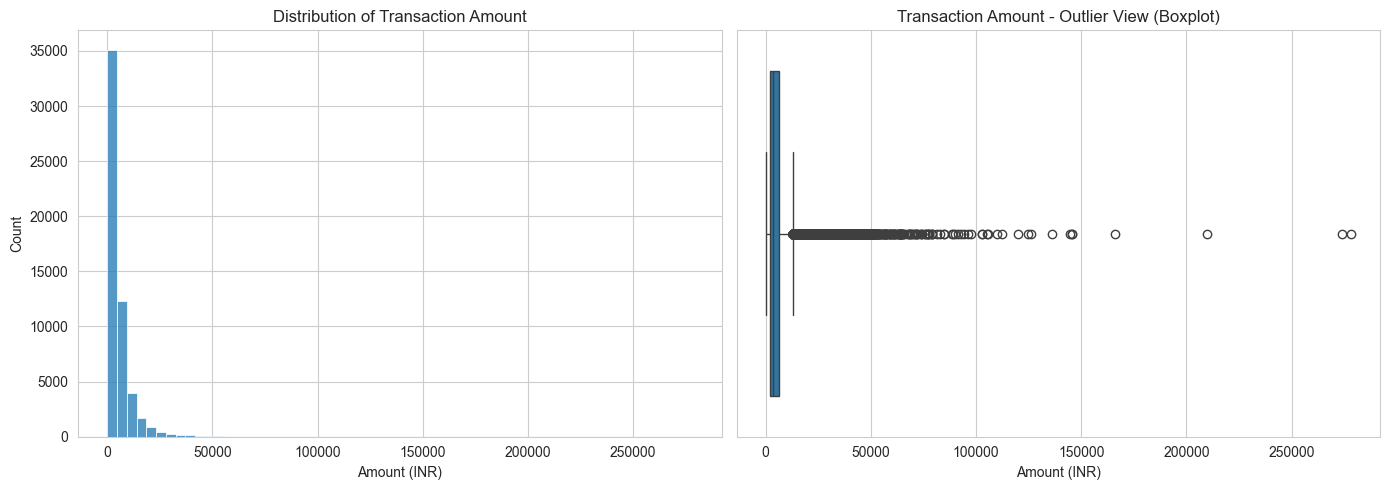

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df.loc[df["amount"] > 0, "amount"], bins=60, ax=ax[0])
ax[0].set_title("Distribution of Transaction Amount")
ax[0].set_xlabel("Amount (INR)")
sns.boxplot(x=df.loc[df["amount"] > 0, "amount"], ax=ax[1])
ax[1].set_title("Transaction Amount - Outlier View (Boxplot)")
ax[1].set_xlabel("Amount (INR)")
plt.tight_layout()
plt.savefig(os.path.join(CHARTS_DIR, "01_amount_distribution.png"), dpi=120)
plt.show()

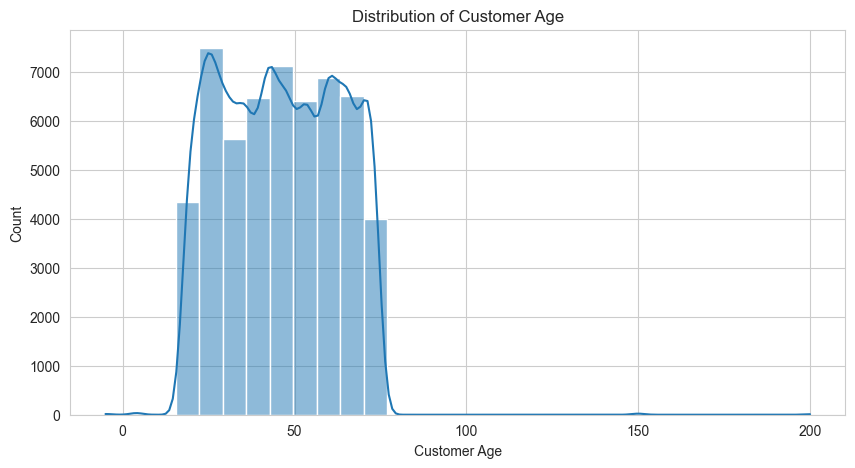

In [11]:
plt.figure(figsize=(10, 5))
sns.histplot(df["customer_age"].dropna(), bins=30, kde=True)
plt.title("Distribution of Customer Age")
plt.xlabel("Customer Age")
plt.savefig(os.path.join(CHARTS_DIR, "02_customer_age_distribution.png"), dpi=120)
plt.show()

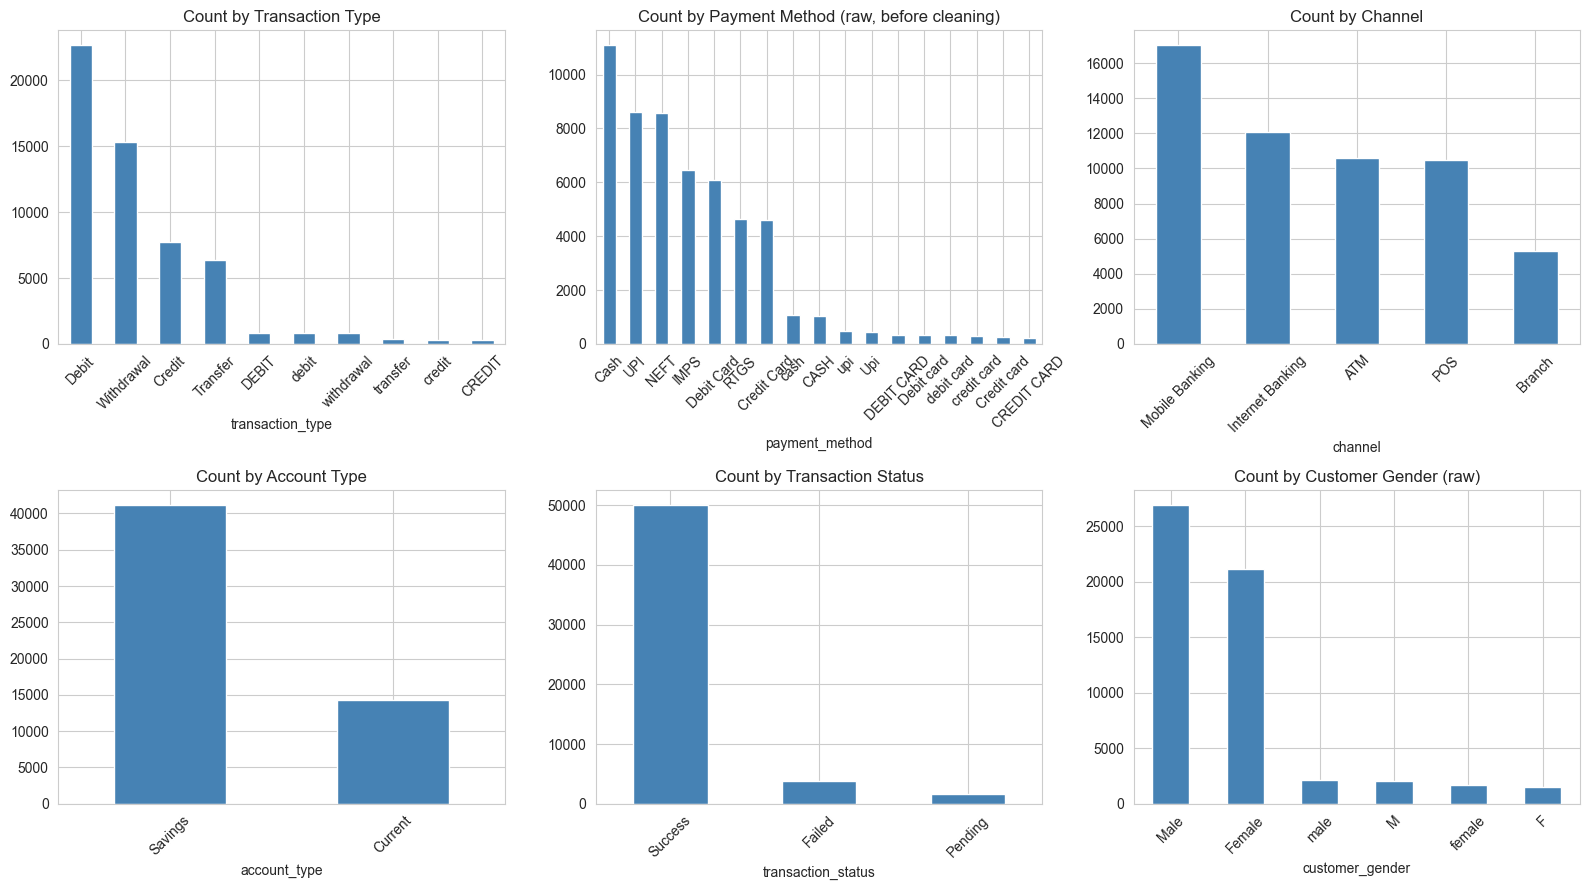

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
plot_specs = [
    ("transaction_type", "Transaction Type"),
    ("payment_method", "Payment Method (raw, before cleaning)"),
    ("channel", "Channel"),
    ("account_type", "Account Type"),
    ("transaction_status", "Transaction Status"),
    ("customer_gender", "Customer Gender (raw)"),
]
for ax, (col, title) in zip(axes.flat, plot_specs):
    df[col].value_counts().plot(kind="bar", ax=ax, color="steelblue")
    ax.set_title(f"Count by {title}")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.savefig(os.path.join(CHARTS_DIR, "03_categorical_counts.png"), dpi=120)
plt.show()

## D. Bivariate Analysis

**Business question:** Does transaction amount vary by transaction type,
payment method, customer age, city or channel? This helps understand which
segments drive transaction value.

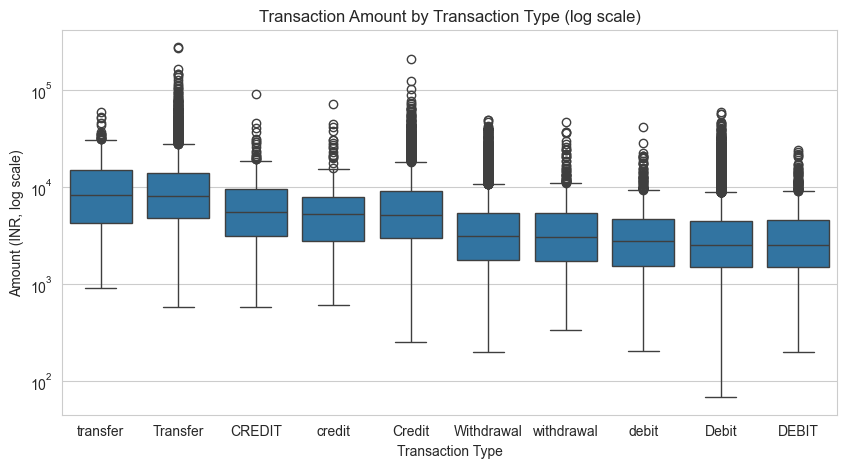

In [13]:
plt.figure(figsize=(10, 5))
order = df.groupby("transaction_type")["amount"].median().sort_values(ascending=False).index
sns.boxplot(data=df[df["amount"] > 0], x="transaction_type", y="amount", order=order)
plt.yscale("log")
plt.title("Transaction Amount by Transaction Type (log scale)")
plt.xlabel("Transaction Type")
plt.ylabel("Amount (INR, log scale)")
plt.savefig(os.path.join(CHARTS_DIR, "04_amount_by_type.png"), dpi=120)
plt.show()

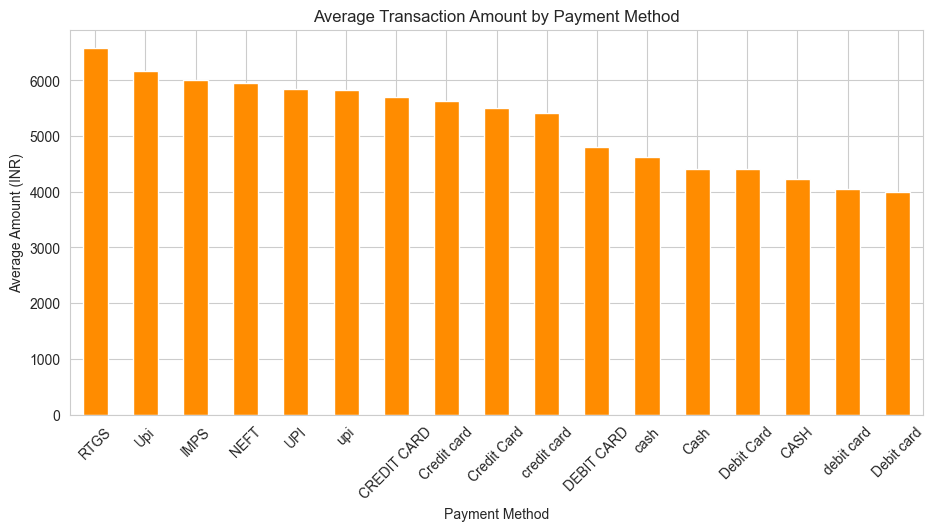

In [14]:
plt.figure(figsize=(11, 5))
avg_by_payment = df[df["amount"] > 0].groupby("payment_method")["amount"].mean().sort_values(ascending=False)
avg_by_payment.plot(kind="bar", color="darkorange")
plt.title("Average Transaction Amount by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Average Amount (INR)")
plt.xticks(rotation=45)
plt.savefig(os.path.join(CHARTS_DIR, "05_avg_amount_by_payment_method.png"), dpi=120)
plt.show()

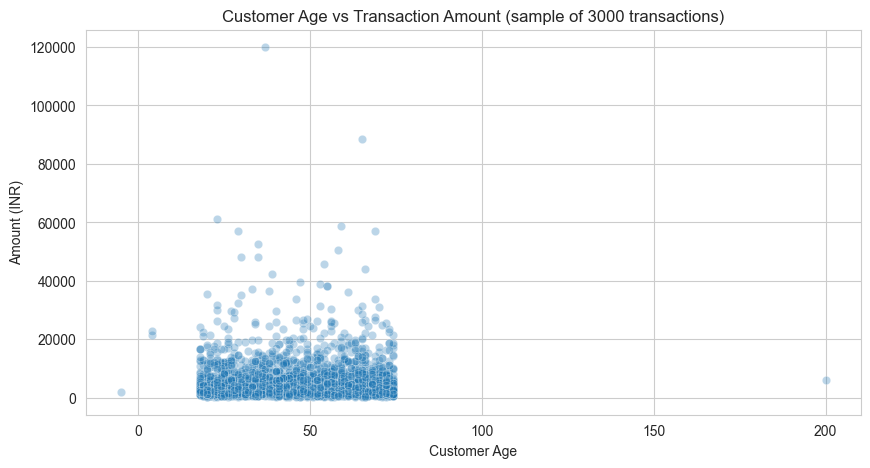

In [15]:
plt.figure(figsize=(10, 5))
sns.scatterplot(data=df[df["amount"] > 0].sample(3000, random_state=42), x="customer_age", y="amount", alpha=0.3)
plt.title("Customer Age vs Transaction Amount (sample of 3000 transactions)")
plt.xlabel("Customer Age")
plt.ylabel("Amount (INR)")
plt.savefig(os.path.join(CHARTS_DIR, "06_age_vs_amount.png"), dpi=120)
plt.show()

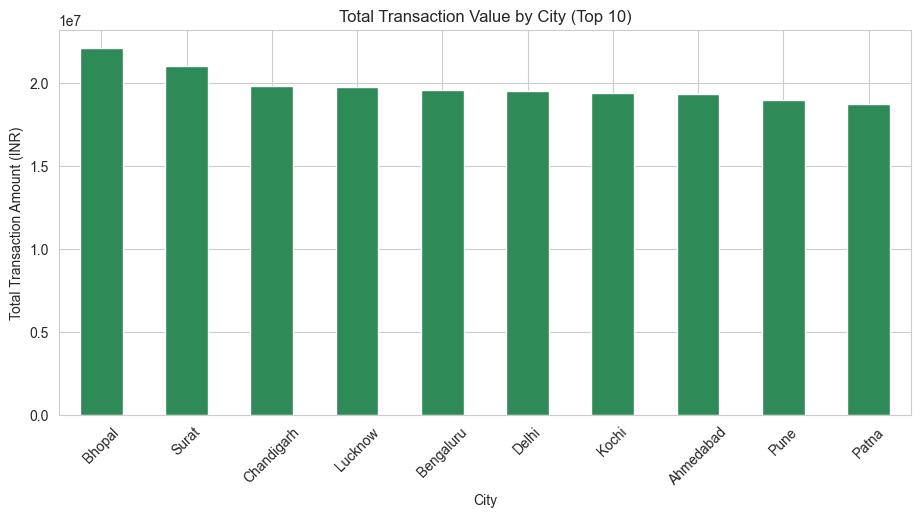

In [16]:
plt.figure(figsize=(11, 5))
top_cities = df.groupby("city")["amount"].sum().sort_values(ascending=False).head(10)
top_cities.plot(kind="bar", color="seagreen")
plt.title("Total Transaction Value by City (Top 10)")
plt.xlabel("City")
plt.ylabel("Total Transaction Amount (INR)")
plt.xticks(rotation=45)
plt.savefig(os.path.join(CHARTS_DIR, "07_amount_by_city.png"), dpi=120)
plt.show()

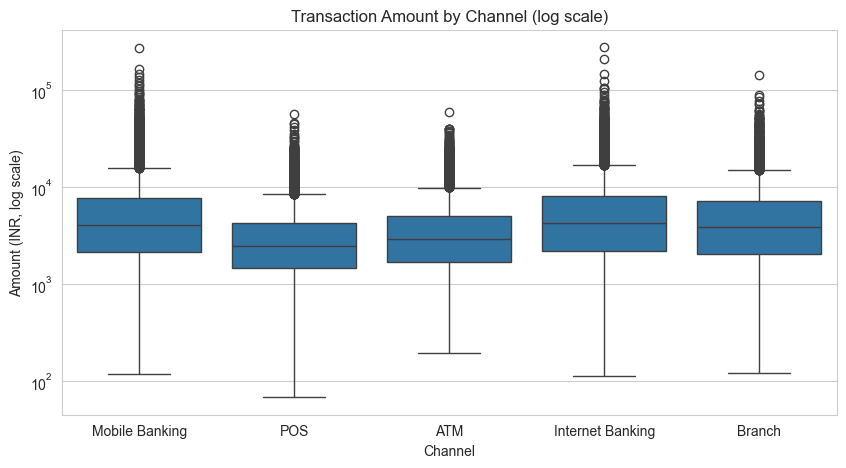

In [17]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df[df["amount"] > 0], x="channel", y="amount")
plt.yscale("log")
plt.title("Transaction Amount by Channel (log scale)")
plt.xlabel("Channel")
plt.ylabel("Amount (INR, log scale)")
plt.savefig(os.path.join(CHARTS_DIR, "08_amount_by_channel.png"), dpi=120)
plt.show()

## E. Time-Series Analysis

**Business question:** How does transaction volume and value change over
days, weeks and months, and how does the success/failure rate trend over
time?

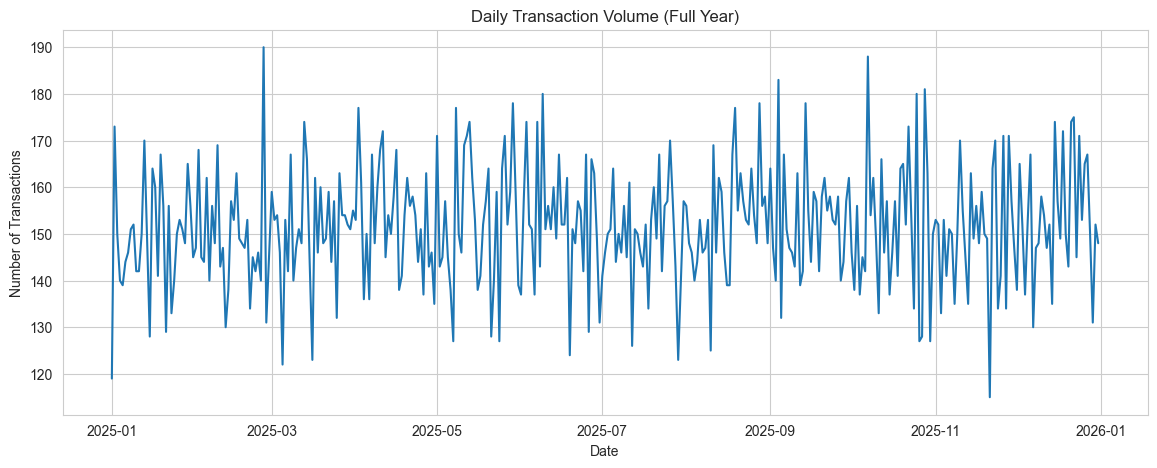

In [18]:
df["transaction_date_parsed"] = pd.to_datetime(df["transaction_date"], errors="coerce", format="%Y-%m-%d")
daily = df.dropna(subset=["transaction_date_parsed"]).groupby(df["transaction_date_parsed"].dt.date).size()

plt.figure(figsize=(14, 5))
daily.plot()
plt.title("Daily Transaction Volume (Full Year)")
plt.xlabel("Date")
plt.ylabel("Number of Transactions")
plt.savefig(os.path.join(CHARTS_DIR, "09_daily_transaction_volume.png"), dpi=120)
plt.show()

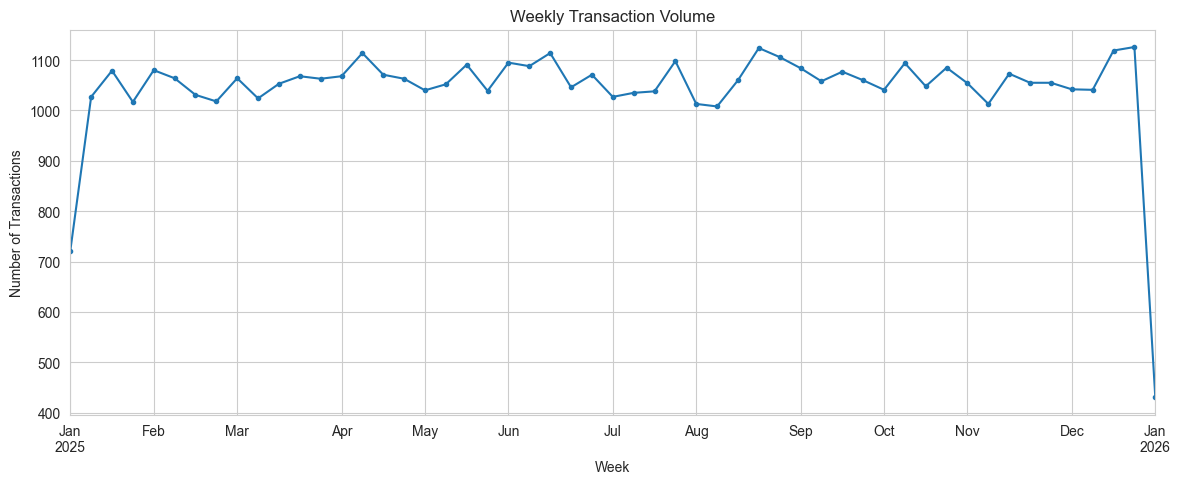

In [19]:
weekly = df.dropna(subset=["transaction_date_parsed"]).set_index("transaction_date_parsed").resample("W").size()
plt.figure(figsize=(14, 5))
weekly.plot(marker="o", markersize=3)
plt.title("Weekly Transaction Volume")
plt.xlabel("Week")
plt.ylabel("Number of Transactions")
plt.savefig(os.path.join(CHARTS_DIR, "10_weekly_transaction_volume.png"), dpi=120)
plt.show()

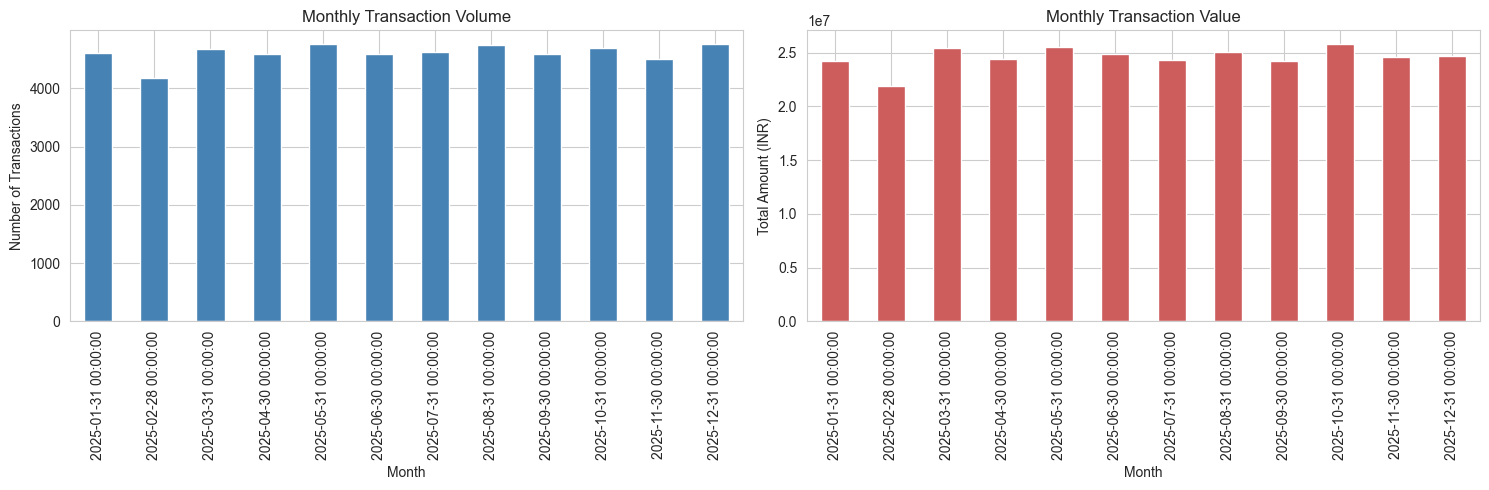

In [20]:
monthly_count = df.dropna(subset=["transaction_date_parsed"]).set_index("transaction_date_parsed").resample("ME").size()
monthly_amount = df.dropna(subset=["transaction_date_parsed"]).set_index("transaction_date_parsed").resample("ME")["amount"].sum()

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
monthly_count.plot(kind="bar", ax=ax[0], color="steelblue")
ax[0].set_title("Monthly Transaction Volume")
ax[0].set_xlabel("Month")
ax[0].set_ylabel("Number of Transactions")

monthly_amount.plot(kind="bar", ax=ax[1], color="indianred")
ax[1].set_title("Monthly Transaction Value")
ax[1].set_xlabel("Month")
ax[1].set_ylabel("Total Amount (INR)")
plt.tight_layout()
plt.savefig(os.path.join(CHARTS_DIR, "11_monthly_volume_value.png"), dpi=120)
plt.show()

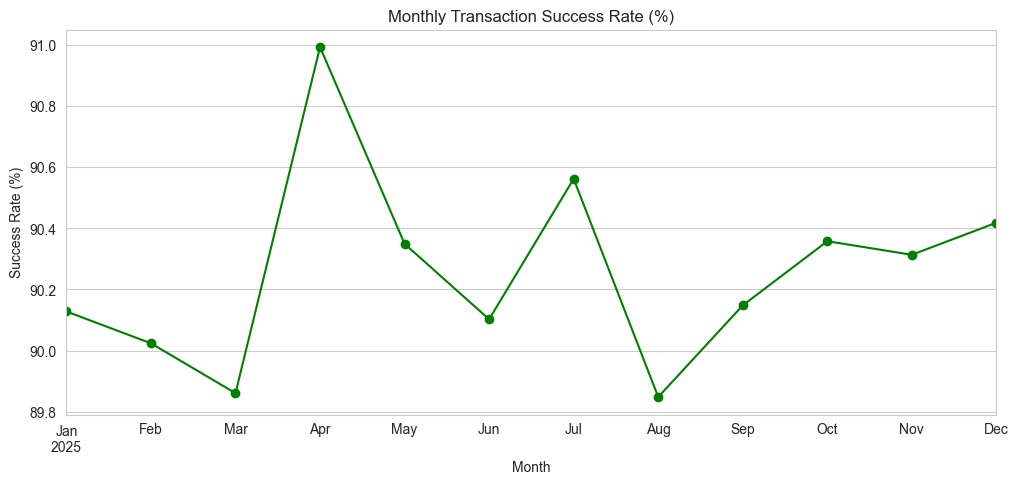

In [21]:
status_trend = df.dropna(subset=["transaction_date_parsed"]).set_index("transaction_date_parsed").resample("ME")["transaction_status"].apply(lambda s: (s == "Success").mean() * 100)
plt.figure(figsize=(12, 5))
status_trend.plot(marker="o", color="green")
plt.title("Monthly Transaction Success Rate (%)")
plt.xlabel("Month")
plt.ylabel("Success Rate (%)")
plt.savefig(os.path.join(CHARTS_DIR, "12_success_rate_trend.png"), dpi=120)
plt.show()

## F. Customer Analysis

**Business question:** Who are our most valuable and most active customers?

In [22]:
customer_summary = df[df["amount"] > 0].groupby("customer_id").agg(
    total_transactions=("transaction_id", "count"),
    total_amount=("amount", "sum"),
    avg_amount=("amount", "mean"),
).reset_index()

print("Transactions per customer - summary stats")
print(customer_summary["total_transactions"].describe())

top_spenders = customer_summary.sort_values("total_amount", ascending=False).head(10)
top_spenders

Transactions per customer - summary stats
count    4000.000000
mean       13.790500
std         6.129397
min         2.000000
25%         9.000000
50%        12.000000
75%        18.000000
max        37.000000
Name: total_transactions, dtype: float64


,customer_id,total_transactions,total_amount,avg_amount
1042,CUST001043,27,416295.90,15418.366667
258,CUST000259,17,336119.19,19771.717059
971,CUST000972,31,313731.41,10120.368065
3728,CUST003729,31,290814.62,9381.116774
1714,CUST001715,35,259253.23,7407.235143
2878,CUST002879,26,252549.75,9713.451923
1808,CUST001809,10,251404.67,25140.467000
1629,CUST001630,14,242528.54,17323.467143
1620,CUST001621,26,241769.69,9298.834231
2128,CUST002129,22,241273.68,10966.985455


In [23]:
most_active = customer_summary.sort_values("total_transactions", ascending=False).head(10)
most_active

,customer_id,total_transactions,total_amount,avg_amount
939,CUST000940,37,195430.47,5281.904595
3414,CUST003415,37,197719.63,5343.773784
1383,CUST001384,36,143581.03,3988.361944
444,CUST000445,36,195403.99,5427.888611
990,CUST000991,35,162700.92,4648.597714
1714,CUST001715,35,259253.23,7407.235143
455,CUST000456,34,145708.60,4285.547059
3714,CUST003715,34,191623.85,5635.995588
919,CUST000920,34,191222.28,5624.184706
320,CUST000321,33,108535.62,3288.958182


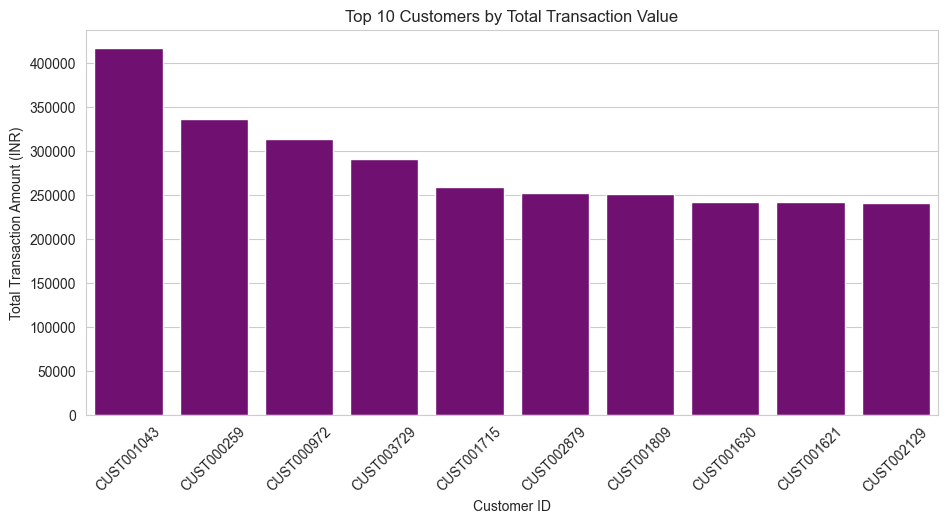

In [24]:
plt.figure(figsize=(11, 5))
sns.barplot(data=top_spenders, x="customer_id", y="total_amount", color="purple")
plt.title("Top 10 Customers by Total Transaction Value")
plt.xlabel("Customer ID")
plt.ylabel("Total Transaction Amount (INR)")
plt.xticks(rotation=45)
plt.savefig(os.path.join(CHARTS_DIR, "13_top_customers_by_value.png"), dpi=120)
plt.show()

## G. Banking Analysis

**Business question:** How do debit/credit/withdrawal/transfer patterns,
channel usage, payment methods, and branch performance compare?

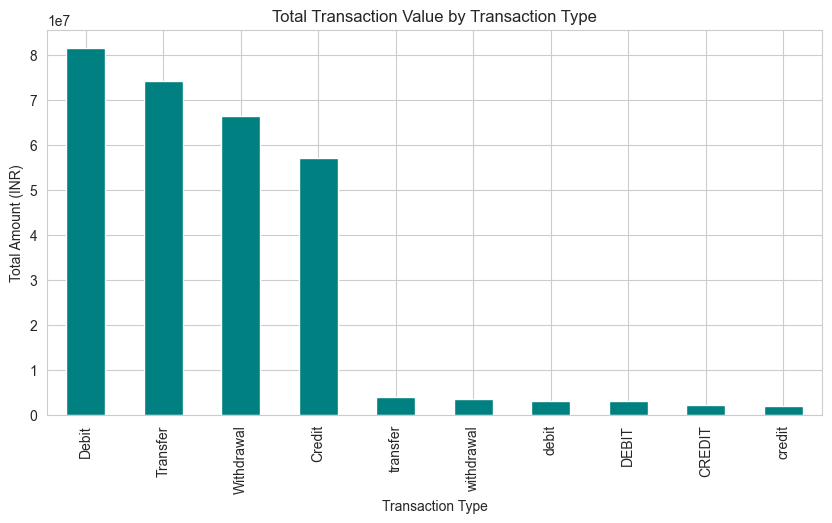

In [25]:
plt.figure(figsize=(10, 5))
type_amount = df[df["amount"] > 0].groupby("transaction_type")["amount"].sum().sort_values(ascending=False)
type_amount.plot(kind="bar", color="teal")
plt.title("Total Transaction Value by Transaction Type")
plt.xlabel("Transaction Type")
plt.ylabel("Total Amount (INR)")
plt.savefig(os.path.join(CHARTS_DIR, "14_total_value_by_type.png"), dpi=120)
plt.show()

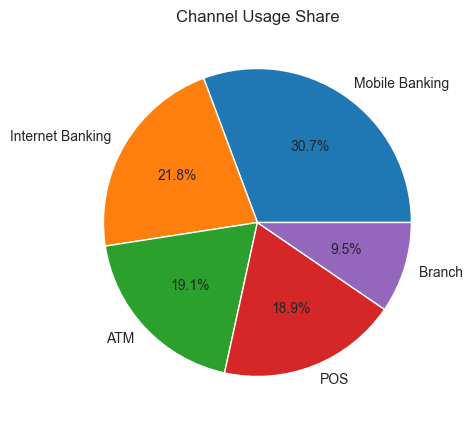

In [26]:
plt.figure(figsize=(10, 5))
channel_usage = df["channel"].value_counts()
channel_usage.plot(kind="pie", autopct="%1.1f%%", ylabel="")
plt.title("Channel Usage Share")
plt.savefig(os.path.join(CHARTS_DIR, "15_channel_usage_share.png"), dpi=120)
plt.show()

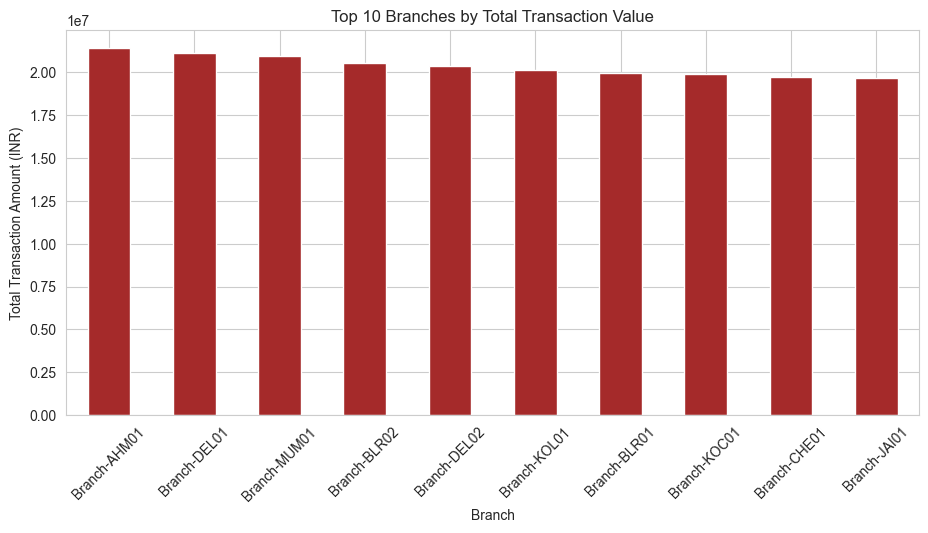

In [27]:
plt.figure(figsize=(11, 5))
branch_perf = df[df["amount"] > 0].groupby("branch")["amount"].sum().sort_values(ascending=False).head(10)
branch_perf.plot(kind="bar", color="brown")
plt.title("Top 10 Branches by Total Transaction Value")
plt.xlabel("Branch")
plt.ylabel("Total Transaction Amount (INR)")
plt.xticks(rotation=45)
plt.savefig(os.path.join(CHARTS_DIR, "16_top_branches.png"), dpi=120)
plt.show()

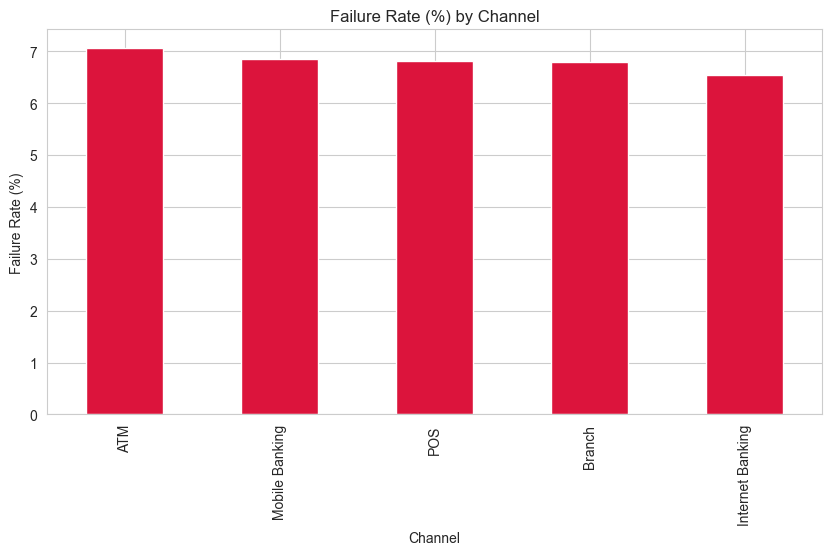

In [28]:
plt.figure(figsize=(10, 5))
channel_fail_rate = df.groupby("channel")["transaction_status"].apply(lambda s: (s == "Failed").mean() * 100).sort_values(ascending=False)
channel_fail_rate.plot(kind="bar", color="crimson")
plt.title("Failure Rate (%) by Channel")
plt.xlabel("Channel")
plt.ylabel("Failure Rate (%)")
plt.savefig(os.path.join(CHARTS_DIR, "17_failure_rate_by_channel.png"), dpi=120)
plt.show()

## Summary of EDA Findings

- The raw dataset has realistic data-quality issues (missing values,
  duplicate transaction IDs/rows, invalid amounts, invalid dates, and
  inconsistent capitalization in categorical fields) that are handled in
  the cleaning stage.
- Transaction amount is right-skewed with a long tail — consistent with
  real banking data (most transactions are small/medium, a few are large).
- `Debit`/`Withdrawal` transactions dominate by count while `Transfer`/
  `Credit` transactions tend to have higher average value.
- Mobile Banking and ATM are the most used channels; ATM/Branch channels
  show comparatively higher failure rates.
- Transaction volume is fairly stable across the year with some monthly
  variation; success rate stays consistently high (~90%).
- A small group of customers accounts for disproportionately high
  transaction value and frequency — useful for both business (VIP
  customers) and risk analysis (high-activity accounts).

These findings directly inform the cleaning rules (`data_cleaning.py`),
the PySpark ETL aggregates, and the SQL/risk analysis queries used later
in this project.
